# EEG .set Reader — Smartick Dataset (OpenNeuro ds006260)

Loads EEGLAB `.set` files with MNE and plots the **signal graphs** (time-series traces).
Example: `sub-Rc01`, `ses-1`, `run-1` (rest) / `run-2` (reading).

In [1]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

%matplotlib inline

ROOT = Path().resolve().parent
OUT = Path().resolve() / "results" / "eeg"
OUT.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT)
print("mne version:", mne.__version__)

ROOT: /Users/ananyosen/Documents/Term Project
mne version: 1.13.2


In [2]:
def get_eeg_path(subject="sub-Rc01", ses="ses-1", run="run-1"):
    """Return path to .set file for given subject/session/run."""
    return (
        ROOT
        / subject
        / ses
        / "eeg"
        / f"{subject}_{ses}_task-SmartickDataset_{run}_eeg.set"
    )


def load_eeg(subject="sub-Rc01", ses="ses-1", run="run-1", preload=True):
    """Load a single .set file as MNE Raw object."""
    path = get_eeg_path(subject, ses, run)
    if not path.exists():
        raise FileNotFoundError(f"EEG file not found: {path}")
    raw = mne.io.read_raw_eeglab(path, preload=preload, verbose=False)
    return raw

In [3]:
for run in ["run-1", "run-2"]:
    raw = load_eeg(subject="sub-Rc01", ses="ses-1", run=run)
    print(f"\n=== sub-Rc01 ses-1 {run} ===")
    print(raw.info)
    print("data shape (n_channels, n_times):", raw.get_data().shape)


=== sub-Rc01 ses-1 run-1 ===
<Info | 8 non-empty values
 bads: []
 ch_names: FP1, FP2, F7, F3, Fz, F4, F8, FT10, FT9, T7, FC5, C3, FC1, FC2, ...
 chs: 32 EEG
 custom_ref_applied: False
 dig: 32 items (32 EEG)
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: unspecified
 nchan: 32
 projs: []
 sfreq: 256.0 Hz
>
data shape (n_channels, n_times): (32, 46080)

=== sub-Rc01 ses-1 run-2 ===
<Info | 8 non-empty values
 bads: []
 ch_names: FP1, FP2, F7, F3, Fz, F4, F8, FT10, FT9, T7, FC5, C3, FC1, FC2, ...
 chs: 32 EEG
 custom_ref_applied: False
 dig: 32 items (32 EEG)
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: unspecified
 nchan: 32
 projs: []
 sfreq: 256.0 Hz
>
data shape (n_channels, n_times): (32, 57439)


## Signal graphs (time-series)

The `.set` file stores one continuous trace per channel. Below we plot the first 10 seconds so the signals are visible (full 3–4 min is too compressed to see).

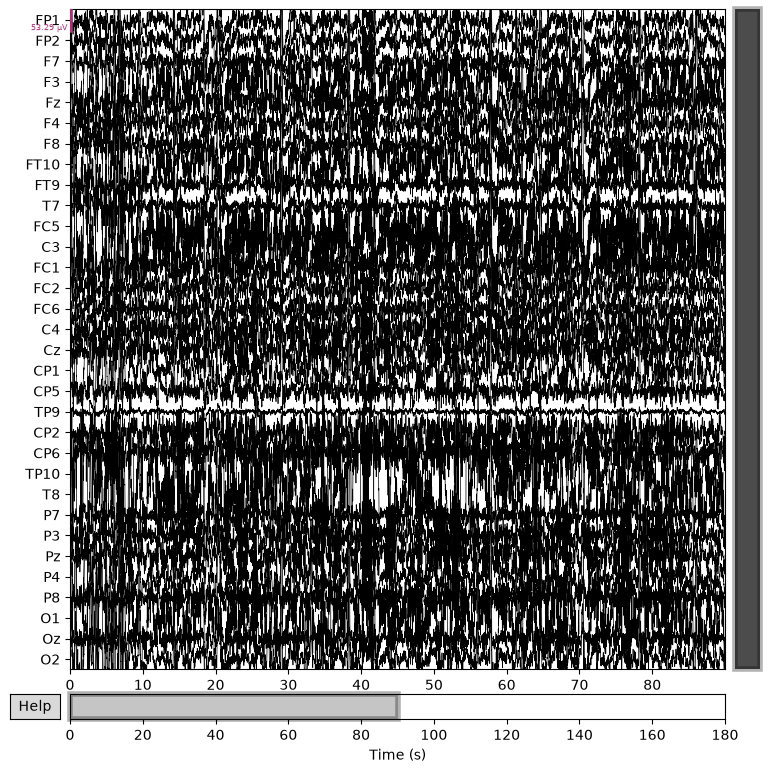

In [14]:
# --- MNE overview: all 32 channels, first 10 s, run-1 (rest) ---
raw_r1 = load_eeg(subject="sub-Rc01", ses="ses-1", run="run-1")
fig = raw_r1.plot(duration=90, n_channels=32, show=False, scalings="auto", title="sub-Rc01 ses-1 run-1 — first 10 s (all channels)")
fig.savefig(OUT / "signal_run-1_allch_10s.png", dpi=150, bbox_inches="tight")
plt.show()

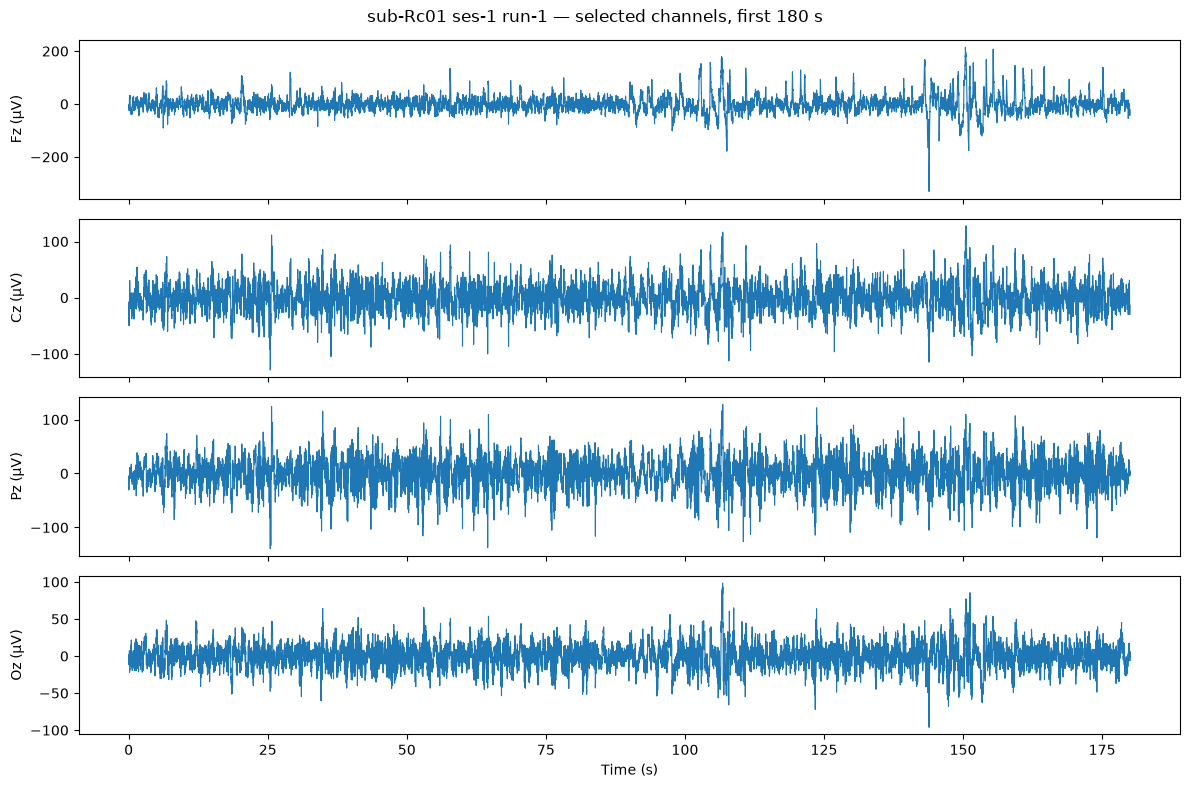

In [15]:
# --- Zoomed traces: 4 selected channels, first 10 s, run-1 ---
sfreq = raw_r1.info["sfreq"]
n_show = int(180 * sfreq)  # 10 seconds
picks = ["Fz", "Cz", "Pz", "Oz"]
data, times = raw_r1[picks, :n_show]

fig, axes = plt.subplots(len(picks), 1, figsize=(12, 8), sharex=True)
for ax, ch_data, ch_name in zip(axes, data, picks):
    ax.plot(times, ch_data * 1e6, linewidth=0.8)  # V -> µV
    ax.set_ylabel(f"{ch_name} (µV)")
axes[-1].set_xlabel("Time (s)")
fig.suptitle("sub-Rc01 ses-1 run-1 — selected channels, first 180 s")
fig.tight_layout()
fig.savefig(OUT / "signal_run-1_selected_10s.png", dpi=150, bbox_inches="tight")
plt.show()

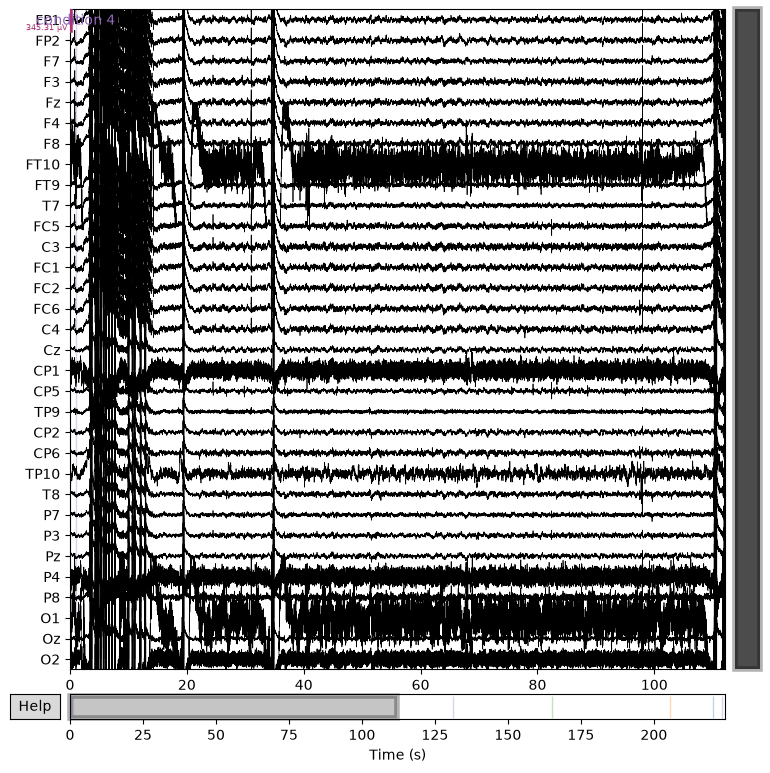

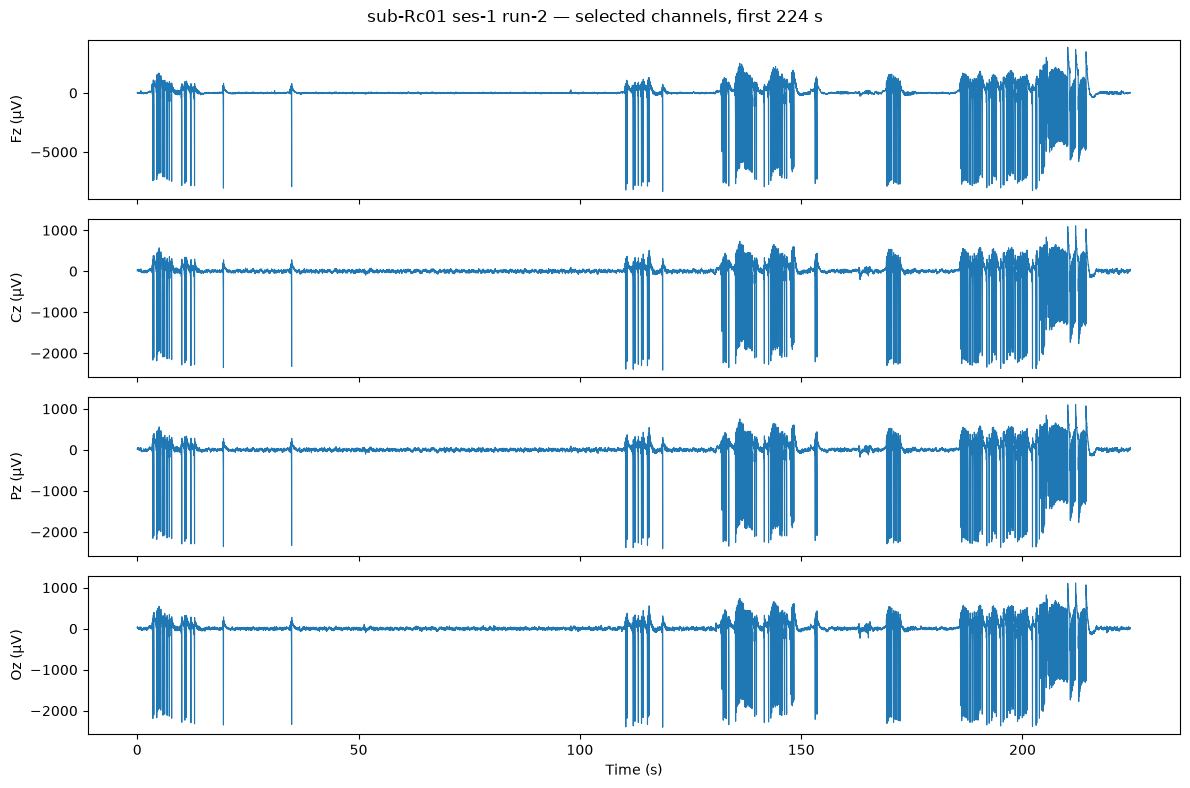

In [16]:
# --- Same signal graphs for run-2 (reading task) ---
raw_r2 = load_eeg(subject="sub-Rc01", ses="ses-1", run="run-2")
fig = raw_r2.plot(duration=112.1, n_channels=32, show=False, scalings="auto", title="sub-Rc01 ses-1 run-2 — first 10 s (all channels)")
fig.savefig(OUT / "signal_run-2_allch_10s.png", dpi=150, bbox_inches="tight")
plt.show()

data2, times2 = raw_r2[picks, :int(224.37109375 * raw_r2.info["sfreq"])]
fig, axes = plt.subplots(len(picks), 1, figsize=(12, 8), sharex=True)
for ax, ch_data, ch_name in zip(axes, data2, picks):
    ax.plot(times2, ch_data * 1e6, linewidth=0.8)
    ax.set_ylabel(f"{ch_name} (µV)")
axes[-1].set_xlabel("Time (s)")
fig.suptitle("sub-Rc01 ses-1 run-2 — selected channels, first 224 s")
fig.tight_layout()
fig.savefig(OUT / "signal_run-2_selected_10s.png", dpi=150, bbox_inches="tight")
plt.show()

## Full `.set` information dump (complete, both runs)

Decodes **every top-level field** stored in the EEGLAB `.set` (MATLAB v5) file, plus the MNE layer. Tables are displayed inline and saved as CSVs to `results/eeg/`.


In [7]:
import scipy.io as sio
import pandas as pd

RUNS = ["run-1", "run-2"]
SUBJECT, SES = "sub-Rc01", "ses-1"

def load_mat(run):
    p = get_eeg_path(SUBJECT, SES, run)
    return sio.loadmat(str(p), struct_as_record=False, squeeze_me=True)

# --- 1. All top-level keys + shape/dtype ---
rows = []
mats = {}
for run in RUNS:
    m = load_mat(run)
    mats[run] = m
    for k, v in m.items():
        if k.startswith('__'):
            continue
        rows.append({"run": run, "key": k,
                     "shape": getattr(v, 'shape', ''),
                     "dtype": str(getattr(v, 'dtype', type(v).__name__))})
df_keys = pd.DataFrame(rows).sort_values(['run','key']).reset_index(drop=True)
df_keys.to_csv(OUT / "mat_keys.csv", index=False)
print(f"top-level keys per run: {df_keys[df_keys.run=='run-1'].shape[0]}")
df_keys.head(50)


top-level keys per run: 43


,run,key,shape,dtype
0,run-1,chaninfo,,mat_struct
1,run-1,chanlocs,"(32,)",object
2,run-1,comments,,str
3,run-1,condition,,str
4,run-1,data,"(32, 46080)",float32
5,run-1,datfile,"(0,)",<U1
6,run-1,dipfit,"(0,)",uint8
7,run-1,epoch,"(0,)",uint8
8,run-1,epochdescription,"(0,)",object
9,run-1,etc,,mat_struct


In [8]:
# --- 2. Header metadata table ---
def scalar(m, k):
    import numpy as np
    v = m[k]
    if isinstance(v, np.ndarray) and v.size == 1:
        v = v.flat[0]
    if isinstance(v, bytes):
        v = v.decode(errors='ignore')
    return v

hrows = []
for run in RUNS:
    m = mats[run]
    hrows.append({
        "run": run,
        "setname": scalar(m,'setname'),
        "filename": scalar(m,'filename'),
        "filepath": scalar(m,'filepath'),
        "subject": scalar(m,'subject'),
        "group": scalar(m,'group'),
        "condition": scalar(m,'condition'),
        "session": scalar(m,'session'),
        "run_field": scalar(m,'run'),
        "ref": scalar(m,'ref'),
        "comments": scalar(m,'comments'),
        "history": scalar(m,'history'),
        "saved": scalar(m,'saved'),
        "datfile": scalar(m,'datfile'),
    })
df_header = pd.DataFrame(hrows)
df_header.to_csv(OUT / "header.csv", index=False)
df_header.T


,0,1
run,run-1,run-2
setname,GDF file,GDF file
filename,sub-Rc01_ses-1_task-SmartickDataset_run-1_eeg.set,sub-Rc01_ses-1_task-SmartickDataset_run-2_eeg.set
filepath,C:\Users\Juan Pablo\Desktop\Neuro materia\BIDS...,C:\Users\Juan Pablo\Desktop\Neuro materia\BIDS...
subject,R_c_01,R_c_01
group,cont,cont
condition,basal,act
session,1,1
run_field,1,1
ref,common,common


In [9]:
# --- 3. Recording params table ---
rrows = []
for run in RUNS:
    m = mats[run]
    t = m['times'].flatten()
    rrows.append({
        "run": run,
        "nbchan": int(scalar(m,'nbchan')),
        "trials": int(scalar(m,'trials')),
        "pnts": int(scalar(m,'pnts')),
        "srate": float(scalar(m,'srate')),
        "xmin_ms": float(scalar(m,'xmin')),
        "xmax_ms": float(scalar(m,'xmax')),
        "times0_ms": float(t[0]),
        "times_last_ms": float(t[-1]),
        "duration_s": float(t[-1]-t[0])/1000,
        "data_shape": str(m['data'].shape),
        "data_dtype": str(m['data'].dtype),
    })
df_rec = pd.DataFrame(rrows)
df_rec.to_csv(OUT / "recording.csv", index=False)
df_rec


,run,nbchan,trials,pnts,srate,xmin_ms,xmax_ms,times0_ms,times_last_ms,duration_s,data_shape,data_dtype
0,run-1,32,1,46080,256.0,0.0,179.996094,0.0,179996.09375,179.996094,"(32, 46080)",float32
1,run-2,32,1,57439,256.0,0.0,224.367188,0.0,224367.18750,224.367188,"(32, 57439)",float32


In [10]:
# --- 4. Channel table (chanlocs full + chaninfo/urchanlocs/spline) ---
def chan_rows(m, run):
    rows = []
    for i, c in enumerate(m['chanlocs'].flatten()):
        g = lambda a: getattr(c, a, '')
        rows.append({"run": run, "idx": i+1, "labels": g('labels'),
                     "theta": g('theta'), "radius": g('radius'),
                     "sph_theta": g('sph_theta'), "sph_phi": g('sph_phi'),
                     "sph_radius": g('sph_radius'),
                     "X": g('X'), "Y": g('Y'), "Z": g('Z'),
                     "type": g('type'), "ref": g('ref'), "urchan": g('urchan')})
    return rows

def struct_fields(o):
    import numpy as np
    if isinstance(o, np.ndarray) and o.size:
        o = o.flat[0]
    return [f for f in dir(o) if not f.startswith('_')]

crow = []
for run in RUNS:
    crow += chan_rows(mats[run], run)
df_chan = pd.DataFrame(crow)
df_chan.to_csv(OUT / "channels_full.csv", index=False)
print("chaninfo fields:", struct_fields(mats['run-2']['chaninfo']))
print("urchanlocs shape:", mats['run-2']['urchanlocs'].shape)
print("splinefile:", repr(scalar(mats['run-2'],'splinefile')))
df_chan.head(35)


chaninfo fields: ['icachansind', 'nodatchans', 'nosedir', 'plotrad', 'shrink']
urchanlocs shape: (0,)
splinefile: array([], dtype='<U1')


,run,idx,labels,theta,radius,sph_theta,sph_phi,sph_radius,X,Y,Z,type,ref,urchan
0,run-1,1,FP1,[],[],[],[],[],[],[],[],[],[],[]
1,run-1,2,FP2,[],[],[],[],[],[],[],[],[],[],[]
2,run-1,3,F7,[],[],[],[],[],[],[],[],[],[],[]
3,run-1,4,F3,[],[],[],[],[],[],[],[],[],[],[]
4,run-1,5,Fz,[],[],[],[],[],[],[],[],[],[],[]
5,run-1,6,F4,[],[],[],[],[],[],[],[],[],[],[]
6,run-1,7,F8,[],[],[],[],[],[],[],[],[],[],[]
7,run-1,8,FT10,[],[],[],[],[],[],[],[],[],[],[]
8,run-1,9,FT9,[],[],[],[],[],[],[],[],[],[],[]
9,run-1,10,T7,[],[],[],[],[],[],[],[],[],[],[]


In [11]:
# --- 5. Event / urevent / epoch tables + MNE annotations + sidecar check ---
erows, urows = [], []
for run in RUNS:
    m = mats[run]
    ev = m['event']
    if ev.size:
        for e in ev.flatten():
            erows.append({"run": run, "type": getattr(e,'type',''),
                          "latency": getattr(e,'latency',''),
                          "duration": getattr(e,'duration',''),
                          "edftype": getattr(e,'edftype',''),
                          "urevent": getattr(e,'urevent','')})
    ue = m['urevent']
    if ue.size:
        for e in ue.flatten():
            urows.append({"run": run, "type": getattr(e,'type',''),
                          "latency": getattr(e,'latency',''),
                          "duration": getattr(e,'duration',''),
                          "edftype": getattr(e,'edftype','')})
df_ev = pd.DataFrame(erows)
df_uev = pd.DataFrame(urows)
if not df_ev.empty: df_ev.to_csv(OUT / "events.csv", index=False)
if not df_uev.empty: df_uev.to_csv(OUT / "urevents.csv", index=False)
print("eventdescription (raw):", mats['run-2']['eventdescription'].shape)
print("epoch size:", mats['run-2']['epoch'].shape, " epochdescription size:", mats['run-2']['epochdescription'].shape)
print("--- MNE annotations ---")
for run in RUNS:
    raw = load_eeg(SUBJECT, SES, run)
    print(f"{run}: {raw.annotations}")
    evts_tsv = ROOT / SUBJECT / SES / "eeg" / f"{SUBJECT}_{SES}_task-SmartickDataset_{run}_events.tsv"
    print(f"  sidecar events.tsv exists: {evts_tsv.exists()}")
    if evts_tsv.exists():
        print(pd.read_csv(evts_tsv, sep='\t').to_string(index=False))
df_ev if not df_ev.empty else "run-1 has no events (continuous rest); run-2 table above"


eventdescription (raw): (5,)
epoch size: (0,)  epochdescription size: (0,)
--- MNE annotations ---
run-1: <Annotations | 0 segments>
  sidecar events.tsv exists: False
run-2: <Annotations | 6 segments: 33026 (1), 33027 (1), 33028 (1), condition 4 (3)>
  sidecar events.tsv exists: True
     onset  duration  sample       value
  0.996094  0.003906     255 condition 4
131.261719  0.003906   33603 condition 4
165.148438  0.003906   42278       33028
205.386719  0.003906   52579       33027
220.332031  0.003906   56405       33026
223.363281  0.003906   57181 condition 4


,run,type,latency,duration,edftype,urevent
0,run-2,condition 4,256,1,4,1
1,run-2,condition 4,33604,1,4,2
2,run-2,33028,42279,1,[],3
3,run-2,33027,52580,1,[],4
4,run-2,33026,56406,1,[],5
5,run-2,condition 4,57182,1,4,6


In [12]:
# --- 6. Data stats: global + per-channel (µV) ---
srows = []
for run in RUNS:
    raw = load_eeg(SUBJECT, SES, run)
    d = raw.get_data() * 1e6  # V -> µV
    print(f"{run}: dtype={raw.get_data().dtype} global min/max/mean µV = {d.min():.1f} / {d.max():.1f} / {d.mean():.4f}")
    for ch, v in zip(raw.ch_names, d):
        srows.append({"run": run, "ch": ch, "min_uV": v.min(), "max_uV": v.max(),
                      "mean_uV": v.mean(), "std_uV": v.std()})
df_stats = pd.DataFrame(srows)
df_stats.to_csv(OUT / "data_stats_per_channel.csv", index=False)
df_stats.head(40)


run-1: dtype=float64 global min/max/mean µV = -109984.2 / 230240.6 / -0.0734
run-2: dtype=float64 global min/max/mean µV = -189304.1 / 247058.8 / 0.0016


,run,ch,min_uV,max_uV,mean_uV,std_uV
0,run-1,FP1,-1292.464478,1635.522217,-0.007020,126.904074
1,run-1,FP2,-912.814209,1376.533569,-0.021219,111.143595
2,run-1,F7,-422.199371,402.396332,0.005345,43.969231
3,run-1,F3,-3039.307617,1700.456421,-0.016167,192.902620
4,run-1,Fz,-330.431396,214.805847,-0.027300,33.077089
5,run-1,F4,-342.256592,222.119598,-0.041051,32.044752
6,run-1,F8,-316.741821,287.583160,-0.050863,33.643320
7,run-1,FT10,-2321.606201,1648.222656,-0.016775,178.203570
8,run-1,FT9,-311.713348,241.760147,-0.002610,28.180957
9,run-1,T7,-313.188782,294.342590,0.000499,30.575025


In [13]:
# --- 7. Empty-slot proof + MNE info dump ---
import numpy as np
def sfields(o):
    if isinstance(o, np.ndarray) and o.size:
        o = o.flat[0]
    return [f for f in dir(o) if not f.startswith('_')]
for run in RUNS:
    m = mats[run]
    print(f"===== {run} =====")
    for k in ['icaact','icawinv','icasphere','icaweights','icachansind',
              'specdata','specicaact','dipfit','roi','epoch',
              'epochdescription','eventdescription','urchanlocs','datfile']:
        v = m[k]
        shp = getattr(v, 'shape', '')
        print(f"  {k}: shape={shp}")
    for k in ['reject','stats','etc','chaninfo']:
        print(f"  {k} fields: {sfields(m[k])}")
    raw = load_eeg(SUBJECT, SES, run)
    print(f"  MNE info keys: {sorted(raw.info.keys())}")
    print(f"  bads={raw.info['bads']} highpass={raw.info['highpass']} lowpass={raw.info['lowpass']} meas_date={raw.info['meas_date']}")
    print(f"  dig[0]={raw.info['dig'][0]} (nan = no digitization in .set)")
    print(f"  projs={raw.info['projs']} comps={raw.info.get('comps','n/a')}")


===== run-1 =====
  icaact: shape=(0,)
  icawinv: shape=(0,)
  icasphere: shape=(0,)
  icaweights: shape=(0,)
  icachansind: shape=(0,)
  specdata: shape=(0,)
  specicaact: shape=(0,)
  dipfit: shape=(0,)
  roi: shape=(0,)
  epoch: shape=(0,)
  epochdescription: shape=(0,)
  eventdescription: shape=(0,)
  urchanlocs: shape=(0,)
  datfile: shape=(0,)
  reject fields: ['disprej', 'gcompreject', 'icarejconst', 'icarejconstE', 'icarejfreq', 'icarejfreqE', 'icarejjp', 'icarejjpE', 'icarejkurt', 'icarejkurtE', 'icarejmanual', 'icarejmanualE', 'icarejthresh', 'icarejthreshE', 'rejconst', 'rejconstE', 'rejconstcol', 'rejfreq', 'rejfreqE', 'rejfreqcol', 'rejglobal', 'rejglobalE', 'rejjp', 'rejjpE', 'rejjpcol', 'rejkurt', 'rejkurtE', 'rejkurtcol', 'rejmanual', 'rejmanualE', 'rejmanualcol', 'rejthresh', 'rejthreshE', 'rejthreshcol', 'threshentropy', 'threshkurtact', 'threshkurtdist', 'threshold']
  stats fields: ['compenta', 'compentr', 'compkurta', 'compkurtdist', 'compkurtr', 'icajp', 'icajpE',